<a href="https://colab.research.google.com/github/ThePretelR/cassava-disease-model-comparison/blob/main/notebooks/01_exploracion_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import tensorflow as tf
import tensorflow_datasets as tfds

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU disponibles:", gpus)

if gpus:
    print("GPU detectada correctamente")
else:
    print("No se detectó GPU")


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU detectada correctamente


In [2]:
%pip install importlib_resources

In [3]:

import importlib_resources

print("Biblioteca importlib_resources instalada correctamente")


Biblioteca importlib_resources instalada correctamente


In [4]:

import tensorflow_datasets as tfds
import tensorflow as tf

# Nombre y versión del dataset
DATASET_NAME = "cassava"
DATASET_VERSION = "0.1.0"

# Descargar y cargar las particiones oficiales
(ds_train, ds_val, ds_test), ds_info = tfds.load(
    f"{DATASET_NAME}:{DATASET_VERSION}",
    split=["train", "validation", "test"],
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)

print("Dataset cargado correctamente")
print("Nombre:", ds_info.name)
print("Versión:", ds_info.version)

print("\nCantidad de imágenes:")
print("Entrenamiento:", ds_info.splits["train"].num_examples)
print("Validación:", ds_info.splits["validation"].num_examples)
print("Prueba:", ds_info.splits["test"].num_examples)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.F38F3O_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.F38F3O_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.F38F3O_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Dataset cargado correctamente
Nombre: cassava
Versión: 0.1.0

Cantidad de imágenes:
Entrenamiento: 5656
Validación: 1889
Prueba: 1885


## 2. Exploracion de las Clases

In [5]:
# Obtener los nombres de las clases
class_names = ds_info.features["label"].names

print("Número de clases:", len(class_names))
print("\nClases encontradas:")

for i, nombre in enumerate(class_names):
    print(f"{i}: {nombre}")

Número de clases: 5

Clases encontradas:
0: cbb
1: cbsd
2: cgm
3: cmd
4: healthy


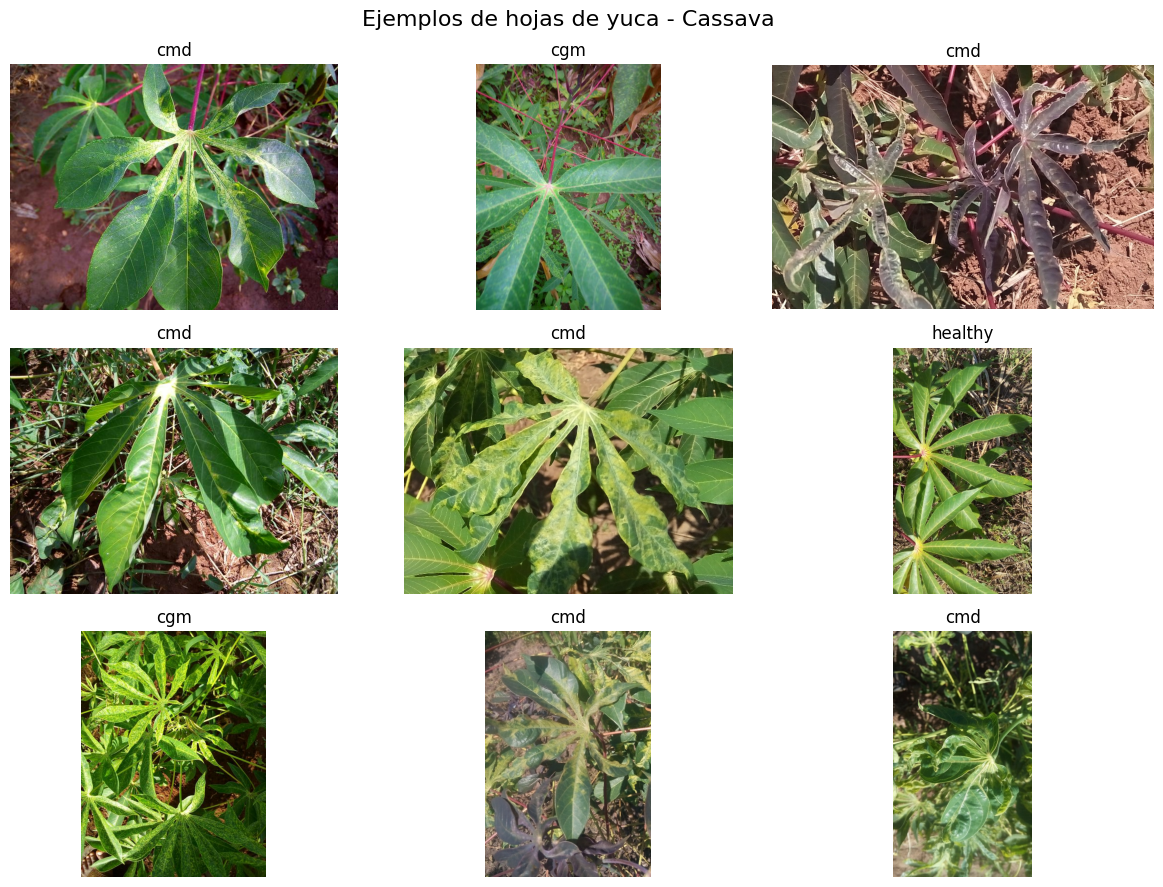

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))

# Mostrar las primeras 9 imágenes de entrenamiento
for i, (imagen, etiqueta) in enumerate(ds_train.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(imagen.numpy())
    plt.title(class_names[int(etiqueta.numpy())])
    plt.axis("off")

plt.suptitle("Ejemplos de hojas de yuca - Cassava", fontsize=16)
plt.tight_layout()
plt.show()

Distribución de clases en entrenamiento:

cbb: 466 imágenes (8.24%)
cbsd: 1443 imágenes (25.51%)
cgm: 773 imágenes (13.67%)
cmd: 2658 imágenes (46.99%)
healthy: 316 imágenes (5.59%)


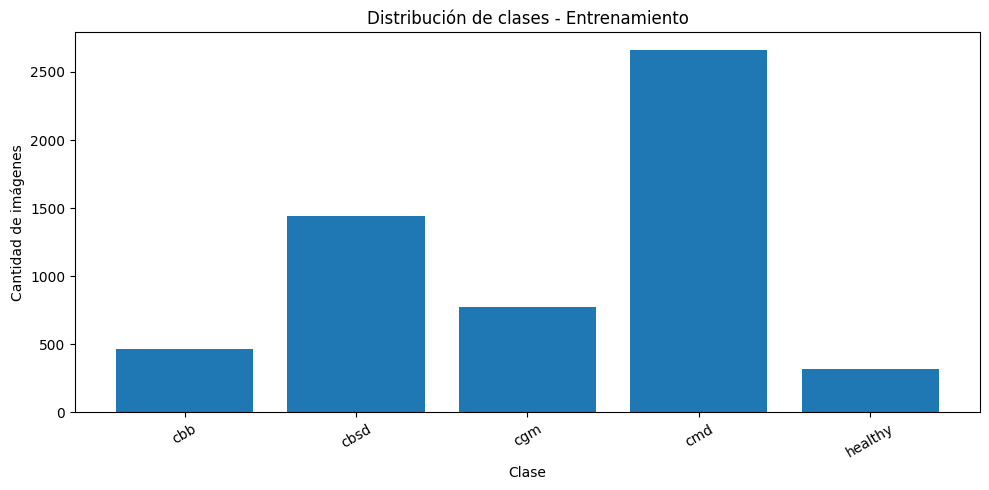

In [7]:

import numpy as np
import matplotlib.pyplot as plt

# Contar las etiquetas del conjunto de entrenamiento
conteos = np.zeros(len(class_names), dtype=int)

for imagen, etiqueta in ds_train:
    conteos[int(etiqueta.numpy())] += 1

# Mostrar resultados
print("Distribución de clases en entrenamiento:\n")

for nombre, cantidad in zip(class_names, conteos):
    porcentaje = cantidad / sum(conteos) * 100
    print(f"{nombre}: {cantidad} imágenes ({porcentaje:.2f}%)")

# Crear gráfica
plt.figure(figsize=(10, 5))
plt.bar(class_names, conteos)

plt.title("Distribución de clases - Entrenamiento")
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 3. Análisis de dimensiones de las imágenes

In [8]:

import numpy as np
from collections import Counter

# Obtener las dimensiones originales
dimensiones = []

for imagen, etiqueta in ds_train:
    alto, ancho, canales = imagen.shape
    dimensiones.append((int(alto), int(ancho)))

# Contar resoluciones
conteo_dimensiones = Counter(dimensiones)

print("Total de imágenes analizadas:", len(dimensiones))
print("Resoluciones diferentes:", len(conteo_dimensiones))

print("\nLas 10 resoluciones más frecuentes:")
for resolucion, cantidad in conteo_dimensiones.most_common(10):
    print(f"{resolucion}: {cantidad} imágenes")

# Estadísticas de tamaño
alturas = np.array([d[0] for d in dimensiones])
anchuras = np.array([d[1] for d in dimensiones])

print("\nAltura mínima:", alturas.min())
print("Altura máxima:", alturas.max())
print("Anchura mínima:", anchuras.min())
print("Anchura máxima:", anchuras.max())

Total de imágenes analizadas: 5656
Resoluciones diferentes: 574

Las 10 resoluciones más frecuentes:
(666, 500): 1442 imágenes
(500, 888): 781 imágenes
(500, 666): 657 imágenes
(500, 625): 635 imágenes
(500, 500): 435 imágenes
(888, 500): 312 imágenes
(500, 499): 29 imágenes
(500, 623): 12 imágenes
(500, 505): 10 imágenes
(500, 609): 9 imágenes

Altura mínima: 347
Altura máxima: 1240
Anchura mínima: 420
Anchura máxima: 1622


## 4. Visualización de imágenes por clase

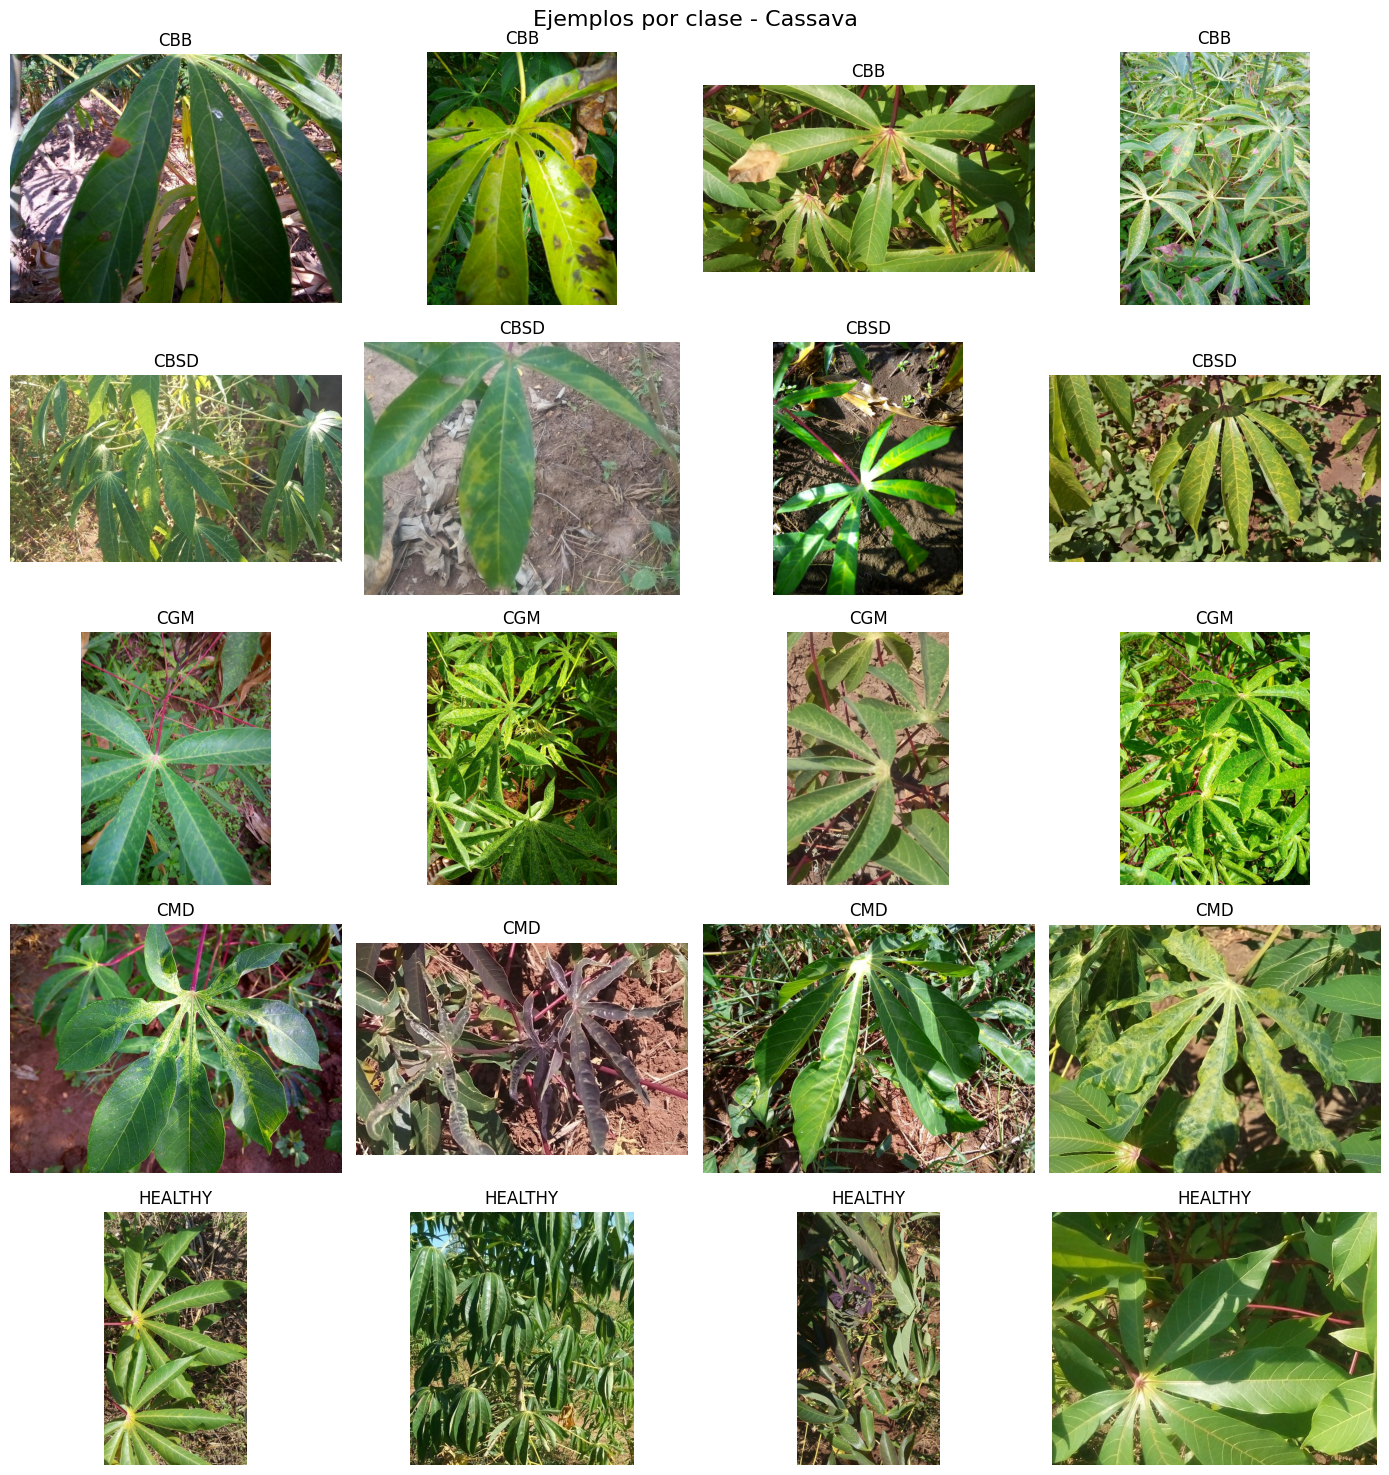

In [9]:

import matplotlib.pyplot as plt
import numpy as np

# Mostrar 4 imágenes de cada clase
ejemplos_por_clase = {i: [] for i in range(len(class_names))}

for imagen, etiqueta in ds_train:
    clase = int(etiqueta.numpy())

    if len(ejemplos_por_clase[clase]) < 4:
        ejemplos_por_clase[clase].append(imagen.numpy())

    if all(len(v) == 4 for v in ejemplos_por_clase.values()):
        break

fig, axes = plt.subplots(
    len(class_names), 4, figsize=(14, 15)
)

for i, nombre in enumerate(class_names):
    for j in range(4):
        axes[i, j].imshow(ejemplos_por_clase[i][j])
        axes[i, j].set_title(nombre.upper())
        axes[i, j].axis("off")

plt.suptitle("Ejemplos por clase - Cassava", fontsize=16)
plt.tight_layout()
plt.show()


## 5. Distribución de dimensiones y relaciones de aspecto

          alto    ancho  relacion_aspecto
count  5656.00  5656.00           5656.00
mean    572.88   610.93              1.12
std     109.93   140.61              0.38
min     347.00   420.00              0.40
25%     500.00   500.00              0.75
50%     500.00   534.00              1.07
75%     666.00   666.00              1.33
max    1240.00  1622.00              3.24


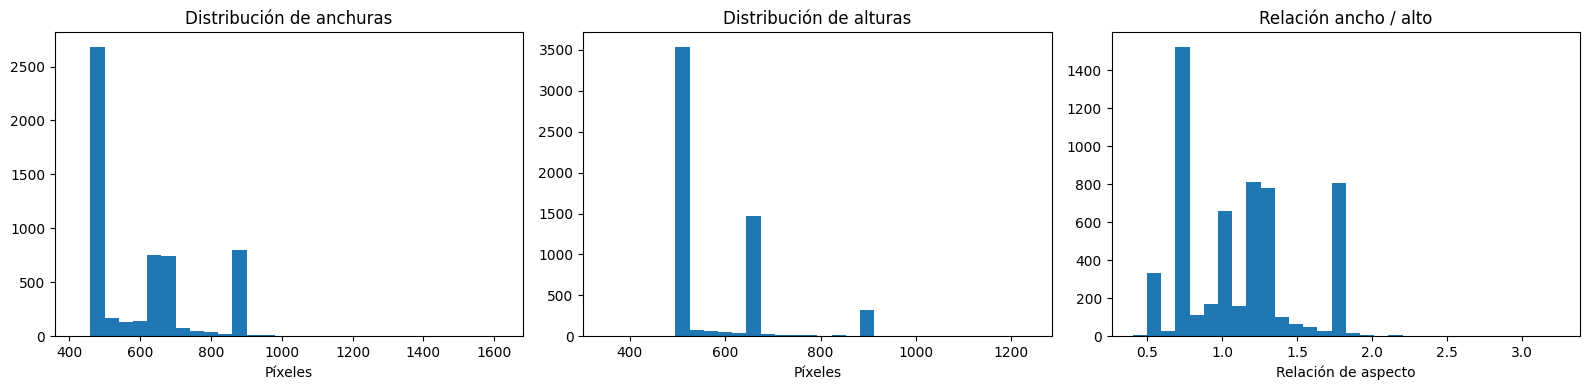

In [10]:

import pandas as pd

df_dimensiones = pd.DataFrame(
    dimensiones,
    columns=["alto", "ancho"]
)

df_dimensiones["relacion_aspecto"] = (
    df_dimensiones["ancho"] / df_dimensiones["alto"]
)

print(df_dimensiones.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df_dimensiones["ancho"], bins=30)
axes[0].set_title("Distribución de anchuras")
axes[0].set_xlabel("Píxeles")

axes[1].hist(df_dimensiones["alto"], bins=30)
axes[1].set_title("Distribución de alturas")
axes[1].set_xlabel("Píxeles")

axes[2].hist(
    df_dimensiones["relacion_aspecto"], bins=30
)
axes[2].set_title("Relación ancho / alto")
axes[2].set_xlabel("Relación de aspecto")

plt.tight_layout()
plt.show()


## 6. Estadísticas de brillo y canales RGB

In [11]:

from tqdm.auto import tqdm

estadisticas = []

for imagen, etiqueta in tqdm(
    ds_train, total=5656, desc="Analizando imágenes"
):
    img = imagen.numpy().astype(np.float32) / 255.0

    rgb = img.mean(axis=(0, 1))
    brillo = np.mean(
        0.299 * img[:, :, 0] +
        0.587 * img[:, :, 1] +
        0.114 * img[:, :, 2]
    )

    estadisticas.append({
        "clase": class_names[int(etiqueta.numpy())],
        "brillo": float(brillo),
        "rojo": float(rgb[0]),
        "verde": float(rgb[1]),
        "azul": float(rgb[2])
    })

df_estadisticas = pd.DataFrame(estadisticas)

print(
    df_estadisticas.groupby("clase")[
        ["brillo", "rojo", "verde", "azul"]
    ].agg(["mean", "std"]).round(3)
)

Analizando imágenes:   0%|          | 0/5656 [00:00<?, ?it/s]

        brillo          rojo         verde          azul       
          mean    std   mean    std   mean    std   mean    std
clase                                                          
cbb      0.463  0.067  0.442  0.077  0.507  0.073  0.297  0.110
cbsd     0.457  0.066  0.438  0.077  0.496  0.071  0.308  0.090
cgm      0.467  0.067  0.442  0.082  0.506  0.072  0.327  0.090
cmd      0.459  0.059  0.448  0.074  0.491  0.061  0.322  0.077
healthy  0.465  0.055  0.441  0.064  0.505  0.062  0.321  0.074


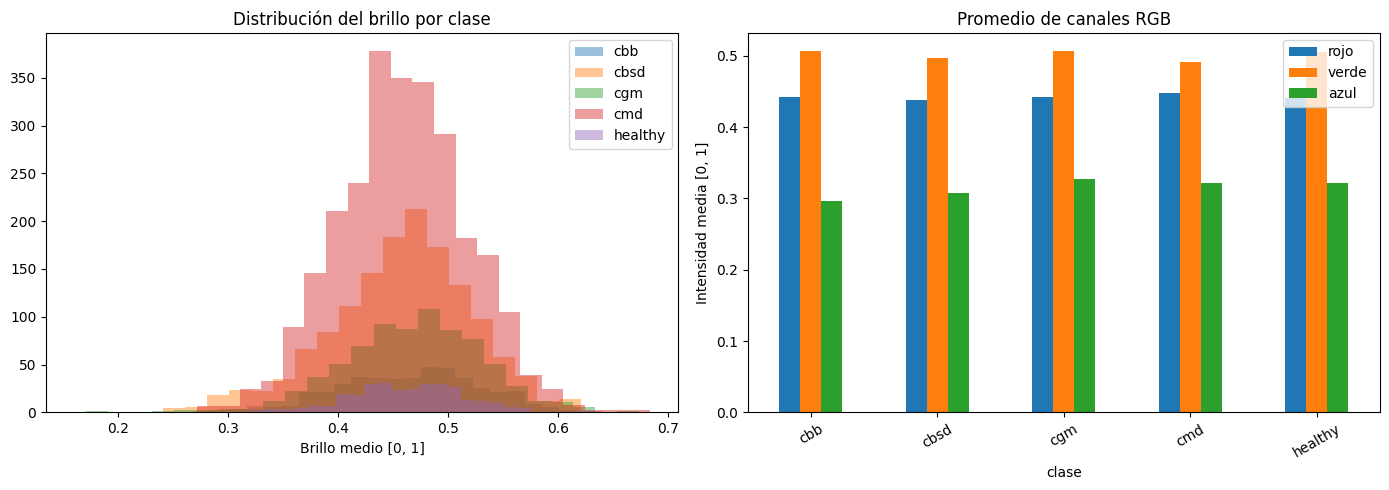

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for clase in class_names:
    valores = df_estadisticas.loc[
        df_estadisticas["clase"] == clase, "brillo"
    ]
    axes[0].hist(
        valores, bins=25, alpha=0.45, label=clase
    )

axes[0].set_title("Distribución del brillo por clase")
axes[0].set_xlabel("Brillo medio [0, 1]")
axes[0].legend()

promedios = df_estadisticas.groupby("clase")[
    ["rojo", "verde", "azul"]
].mean()

promedios.plot(kind="bar", ax=axes[1])
axes[1].set_title("Promedio de canales RGB")
axes[1].set_ylabel("Intensidad media [0, 1]")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 7. Detección de duplicados exactos

In [13]:

import hashlib
from collections import Counter, defaultdict

def obtener_hash(imagen):
    img = imagen.numpy()
    h = hashlib.sha256()
    h.update(str(img.shape).encode("utf-8"))
    h.update(img.tobytes())
    return h.hexdigest()

def calcular_hashes(dataset, nombre):
    registros = []

    for i, (imagen, etiqueta) in enumerate(
        tqdm(dataset, desc=nombre)
    ):
        registros.append({
            "particion": nombre,
            "indice": i,
            "hash": obtener_hash(imagen),
            "clase": class_names[int(etiqueta.numpy())]
        })

    return pd.DataFrame(registros)

hash_train = calcular_hashes(ds_train, "train")
hash_val = calcular_hashes(ds_val, "validation")
hash_test = calcular_hashes(ds_test, "test")

df_hashes = pd.concat(
    [hash_train, hash_val, hash_test],
    ignore_index=True
)

print("Imágenes analizadas:", len(df_hashes))
print("Hashes únicos:", df_hashes["hash"].nunique())


train:   0%|          | 0/5656 [00:00<?, ?it/s]

validation:   0%|          | 0/1889 [00:00<?, ?it/s]

test:   0%|          | 0/1885 [00:00<?, ?it/s]

Imágenes analizadas: 9430
Hashes únicos: 9388


In [14]:

# Duplicados dentro de cada partición
for nombre, grupo in df_hashes.groupby("particion"):
    duplicados = grupo.duplicated("hash").sum()
    print(f"{nombre}: {duplicados} duplicados exactos")

# Comprobar coincidencias entre particiones
particiones = ["train", "validation", "test"]

for i in range(len(particiones)):
    for j in range(i + 1, len(particiones)):
        a = particiones[i]
        b = particiones[j]

        hashes_a = set(
            df_hashes.loc[
                df_hashes["particion"] == a, "hash"
            ]
        )
        hashes_b = set(
            df_hashes.loc[
                df_hashes["particion"] == b, "hash"
            ]
        )

        coincidencias = hashes_a & hashes_b

        print(
            f"{a} vs {b}: "
            f"{len(coincidencias)} hashes compartidos"
        )

# Guardar registros coincidentes para inspección
repetidos = df_hashes[
    df_hashes.duplicated("hash", keep=False)
].sort_values("hash")

print("\nRegistros con hashes repetidos:")
print(repetidos.head(20))


test: 1 duplicados exactos
train: 18 duplicados exactos
validation: 2 duplicados exactos
train vs validation: 11 hashes compartidos
train vs test: 10 hashes compartidos
validation vs test: 4 hashes compartidos

Registros con hashes repetidos:
       particion  indice                                               hash  \
7237  validation    1581  022b3d6752997e08c9d586465c5c33bd80f6e3f9256daf...   
3066       train    3066  022b3d6752997e08c9d586465c5c33bd80f6e3f9256daf...   
9173        test    1628  0406e60ead61df07f8040aa034f0d66582ce3e9903b00d...   
1125       train    1125  0406e60ead61df07f8040aa034f0d66582ce3e9903b00d...   
4081       train    4081  0f31941aa880d5d1ffca637c154b630e1f9e13bb2ce232...   
7635        test      90  0f31941aa880d5d1ffca637c154b630e1f9e13bb2ce232...   
7860        test     315  0f31941aa880d5d1ffca637c154b630e1f9e13bb2ce232...   
6542  validation     886  22cf6aa9258222461a89ed7c7fdb6eb735da650c38f114...   
337        train     337  22cf6aa9258222461a89

In [15]:
%pip install -q ImageHash

In [16]:

import imagehash
from PIL import Image

def obtener_phash(imagen):
    img = Image.fromarray(imagen.numpy())
    return str(imagehash.phash(img))

registros_phash = []

for nombre, dataset in [
    ("train", ds_train),
    ("validation", ds_val),
    ("test", ds_test)
]:
    for i, (imagen, etiqueta) in enumerate(
        tqdm(dataset, desc=f"pHash {nombre}")
    ):
        registros_phash.append({
            "particion": nombre,
            "indice": i,
            "phash": obtener_phash(imagen),
            "clase": class_names[int(etiqueta.numpy())]
        })

df_phash = pd.DataFrame(registros_phash)

print("Imágenes procesadas:", len(df_phash))
print("pHash únicos:", df_phash["phash"].nunique())

pHash train:   0%|          | 0/5656 [00:00<?, ?it/s]

pHash validation:   0%|          | 0/1889 [00:00<?, ?it/s]

pHash test:   0%|          | 0/1885 [00:00<?, ?it/s]

Imágenes procesadas: 9430
pHash únicos: 9381


In [17]:
coincidencias_phash = df_phash[
    df_phash.duplicated("phash", keep=False)
].sort_values("phash")

print(
    "Registros con pHash repetido:",
    len(coincidencias_phash)
)

display(coincidencias_phash.head(30))

Registros con pHash repetido: 82


,particion,indice,phash,clase
2984,train,2984,838b35323c7a077e,cbb
9010,test,1465,838b35323c7a077e,cbsd
638,train,638,838b35323c7a077e,cgm
361,train,361,839c9732bb343636,cbb
2172,train,2172,839c9732bb343636,cbsd
3267,train,3267,839c9732bb343636,cgm
7332,validation,1676,85c33e314dcd4bc6,cmd
8231,test,686,85c33e314dcd4bc6,cmd
5033,train,5033,891ab0a5d68fccdc,cmd
5764,validation,108,891ab0a5d68fccdc,cbb


## 8. Inspección de calidad visual

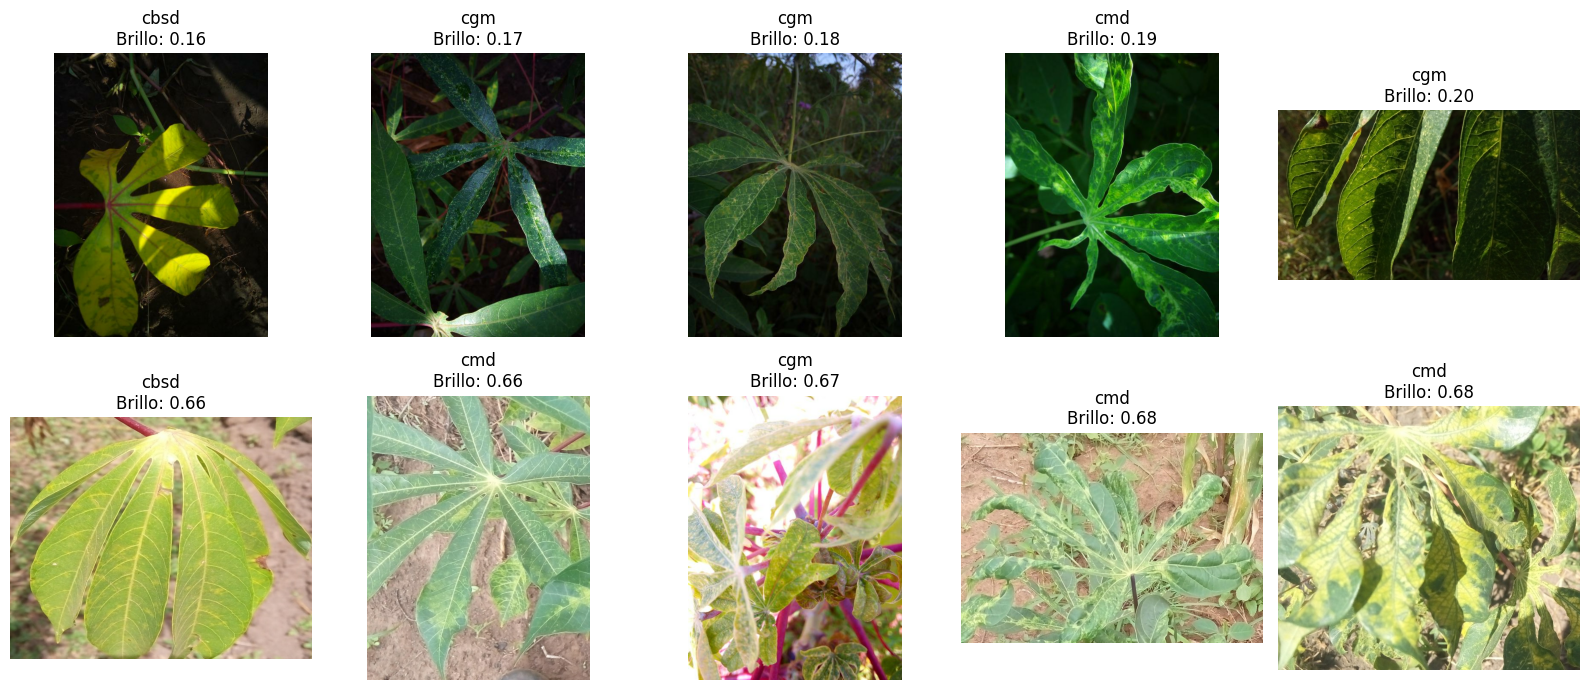

In [18]:
# Seleccionar las 5 imágenes más oscuras
# y las 5 más brillantes de entrenamiento

indices = df_estadisticas.sort_values("brillo")

seleccion = list(indices.head(5).index) + list(
    indices.tail(5).index
)

seleccion_set = set(seleccion)
imagenes_seleccionadas = {}

for i, (imagen, etiqueta) in enumerate(ds_train):
    if i in seleccion_set:
        imagenes_seleccionadas[i] = (
            imagen.numpy(),
            int(etiqueta.numpy())
        )

    if len(imagenes_seleccionadas) == len(seleccion_set):
        break

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for posicion, indice in enumerate(seleccion):
    fila, columna = divmod(posicion, 5)
    imagen, etiqueta = imagenes_seleccionadas[indice]

    axes[fila, columna].imshow(imagen)
    axes[fila, columna].set_title(
        f"{class_names[etiqueta]}\n"
        f"Brillo: {df_estadisticas.loc[indice, 'brillo']:.2f}"
    )
    axes[fila, columna].axis("off")

plt.tight_layout()
plt.show()

## 9. Exportación de resultados

In [19]:
import os

os.makedirs("resultados/eda", exist_ok=True)

df_dimensiones.to_csv(
    "resultados/eda/dimensiones.csv",
    index=False
)

df_estadisticas.to_csv(
    "resultados/eda/estadisticas_color.csv",
    index=False
)

df_hashes.to_csv(
    "resultados/eda/hashes_exactos.csv",
    index=False
)

df_phash.to_csv(
    "resultados/eda/hashes_perceptuales.csv",
    index=False
)

df_conteos = pd.DataFrame({
    "clase": class_names,
    "cantidad": conteos,
    "porcentaje": conteos / conteos.sum() * 100
})

df_conteos.to_csv(
    "resultados/eda/distribucion_clases.csv",
    index=False
)

print("Resultados del EDA exportados correctamente")

Resultados del EDA exportados correctamente
